In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Read CSV
df = pd.read_csv("../csv_files/measurements.csv")

# Ensure numeric columns are properly typed
numeric_cols = ['Powercap', 'Package', 'Core', 'GPU', 'DRAM', 'Time', 'Temperature', 'Memory']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Language     40 non-null     object 
 1   Program      40 non-null     object 
 2   Powercap     40 non-null     int64  
 3   Package      40 non-null     float64
 4   Core         40 non-null     float64
 5   GPU          40 non-null     float64
 6   DRAM         40 non-null     float64
 7   Time         40 non-null     float64
 8   Temperature  40 non-null     float64
 9   Memory       40 non-null     int64  
dtypes: float64(6), int64(2), object(2)
memory usage: 3.2+ KB


In [10]:
# Function to remove 3 min and 3 max Package values per program type
def remove_outliers(df, program_col='Program', target_col='Package'):
    df_clean = pd.DataFrame()
    
    for program_type in df[program_col].unique():
        subset = df[df[program_col] == program_type].copy()
        subset = subset.sort_values(by=target_col)
        if len(subset) > 6:  # ensure enough rows
            subset = subset.iloc[3:-3]  # remove 3 smallest and 3 largest
        df_clean = pd.concat([df_clean, subset])
    
    return df_clean.reset_index(drop=True)

# Apply function
df_clean = remove_outliers(df)
df_clean

,Language,Program,Powercap,Package,Core,GPU,DRAM,Time,Temperature,Memory
0,C,idle_fibonacci,4,35.078064,0.777283,0.146790,16.911438,30005.6,45.0,1152
1,C,idle_fibonacci,4,35.164612,0.800049,0.187073,16.962646,30005.6,46.0,1152
2,C,idle_fibonacci,4,35.179504,0.834717,0.179688,16.963928,30005.7,43.0,1152
3,C,idle_fibonacci,4,35.197571,0.857666,0.182495,16.957642,30005.7,44.0,1152
4,C,idle_fibonacci,4,35.241333,0.668518,0.133728,16.910828,30005.7,42.0,1152
5,C,idle_fibonacci,4,35.370728,0.860474,0.183228,16.960815,30005.6,42.0,1152
6,C,idle_fibonacci,-1,35.427124,0.796143,0.133240,16.916565,30005.7,39.0,1152
7,C,idle_fibonacci,-1,35.434021,0.799133,0.146912,16.913696,30005.7,39.0,1152
8,C,idle_fibonacci,-1,35.454346,0.771240,0.173462,16.954956,30005.7,39.0,1152
9,C,idle_fibonacci,-1,35.464050,0.761169,0.188354,16.954041,30005.7,40.0,1152


In [11]:
non_idle_df = df_clean[~df_clean['Program'].str.contains('idle_fibonacci')].copy()
idle_df = df_clean[df_clean['Program'].str.contains('idle_fibonacci')].copy()

In [12]:
non_idle_df

,Language,Program,Powercap,Package,Core,GPU,DRAM,Time,Temperature,Memory
14,C,fibonacci,4,2385.745300,1694.030396,0.310913,343.909973,603275.0,41.0,1152
15,C,fibonacci,4,2385.918640,1693.115479,0.317444,343.927612,603349.0,41.0,1152
16,C,fibonacci,4,2386.088928,1699.247253,0.327332,343.872742,603372.0,42.0,1152
17,C,fibonacci,4,2386.893616,1694.100281,0.316711,344.075562,603603.0,41.0,1152
18,C,fibonacci,4,2387.707275,1694.594543,0.317200,344.247375,603799.0,41.0,1152
19,C,fibonacci,4,2390.973694,1697.119812,0.325867,344.924255,604603.0,41.0,1152
20,C,fibonacci,4,2398.294067,1701.564941,0.328186,347.249268,606512.0,41.0,1152
21,C,fibonacci,-1,4551.022156,4219.181396,0.272339,165.621948,288839.0,48.0,1152
22,C,fibonacci,-1,4608.785339,4274.076965,0.381775,165.601440,288728.0,48.0,1152
23,C,fibonacci,-1,4627.606750,4294.272339,0.445923,165.225952,288809.0,48.0,1152


In [13]:
idle_df

,Language,Program,Powercap,Package,Core,GPU,DRAM,Time,Temperature,Memory
0,C,idle_fibonacci,4,35.078064,0.777283,0.146790,16.911438,30005.6,45.0,1152
1,C,idle_fibonacci,4,35.164612,0.800049,0.187073,16.962646,30005.6,46.0,1152
2,C,idle_fibonacci,4,35.179504,0.834717,0.179688,16.963928,30005.7,43.0,1152
3,C,idle_fibonacci,4,35.197571,0.857666,0.182495,16.957642,30005.7,44.0,1152
4,C,idle_fibonacci,4,35.241333,0.668518,0.133728,16.910828,30005.7,42.0,1152
5,C,idle_fibonacci,4,35.370728,0.860474,0.183228,16.960815,30005.6,42.0,1152
6,C,idle_fibonacci,-1,35.427124,0.796143,0.133240,16.916565,30005.7,39.0,1152
7,C,idle_fibonacci,-1,35.434021,0.799133,0.146912,16.913696,30005.7,39.0,1152
8,C,idle_fibonacci,-1,35.454346,0.771240,0.173462,16.954956,30005.7,39.0,1152
9,C,idle_fibonacci,-1,35.464050,0.761169,0.188354,16.954041,30005.7,40.0,1152


In [14]:
num_cols = ['Package', 'Core', 'GPU', 'DRAM']

id_cols = ['Language', 'Program', 'Powercap', 'Time', 'Temperature', 'Memory']

non_idle_reset = non_idle_df.reset_index(drop=True)
idle_reset = idle_df.reset_index(drop=True)

diff_df = non_idle_reset[id_cols].copy()
diff_df[num_cols] = non_idle_reset[num_cols] - idle_reset[num_cols]

diff_df


,Language,Program,Powercap,Time,Temperature,Memory,Package,Core,GPU,DRAM
0,C,fibonacci,4,603275.0,41.0,1152,2350.667236,1693.253113,0.164124,326.998535
1,C,fibonacci,4,603349.0,41.0,1152,2350.754028,1692.315430,0.130371,326.964966
2,C,fibonacci,4,603372.0,42.0,1152,2350.909424,1698.412537,0.147644,326.908813
3,C,fibonacci,4,603603.0,41.0,1152,2351.696045,1693.242615,0.134216,327.117920
4,C,fibonacci,4,603799.0,41.0,1152,2352.465942,1693.926025,0.183472,327.336548
5,C,fibonacci,4,604603.0,41.0,1152,2355.602966,1696.259338,0.142639,327.963440
6,C,fibonacci,4,606512.0,41.0,1152,2362.866943,1700.768799,0.194946,330.332703
7,C,fibonacci,-1,288839.0,48.0,1152,4515.588135,4218.382263,0.125427,148.708252
8,C,fibonacci,-1,288728.0,48.0,1152,4573.330994,4273.305725,0.208313,148.646484
9,C,fibonacci,-1,288809.0,48.0,1152,4592.142700,4293.511169,0.257568,148.271912


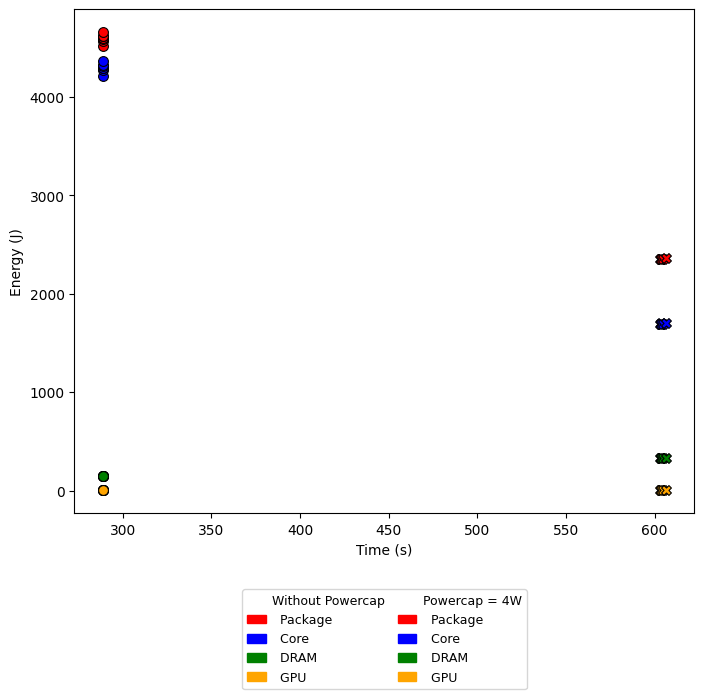

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Energy columns
energy_cols = ['Package', 'Core', 'DRAM', 'GPU']
energy_colors = ['red', 'blue', 'green', 'orange']
powercaps = sorted(diff_df['Powercap'].unique())

plt.figure(figsize=(8,8))

markers = ['o', 'X', 's', '^', 'D', 'v']
for i, col in enumerate(energy_cols):
    for j, pc in enumerate(powercaps):
        subset = diff_df[diff_df['Powercap'] == pc]
        plt.scatter(
            subset['Time'] / 1000.0,
            subset[col],
            color=energy_colors[i],
            marker=markers[j % len(markers)],
            s=50,
            edgecolors='black',
            linewidths=0.8
        )

plt.xlabel('Time (s)')
plt.ylabel('Energy (J)')
plt.title('')

patches = []
for pc in powercaps:
    label_group = "Without Powercap" if pc == -1 else f"Powercap = {pc}W"
    patches.append(mpatches.Patch(color='none', label=label_group))
    for i, col in enumerate(energy_cols):
        patches.append(mpatches.Patch(color=energy_colors[i], label=f"  {col}"))

plt.legend(
    handles=patches,
    title="",
    frameon=True,
    bbox_to_anchor=(0.5, -0.15),
    loc='upper center',
    borderaxespad=0,
    fontsize=9,
    ncol=2,
    columnspacing=1.0,
    handletextpad=0.5,
    handlelength=1.5,
)

plt.subplots_adjust(bottom=0.25)
#plt.savefig("std.pdf", format='pdf', bbox_inches='tight')
plt.show()

